# Group Project - Safe routes home at night 

**DS105A Group Project – Data for Data Science (Autumn Term 2025/2026)**

<div style="font-family: system-ui; padding: 20px 30px 20px 20px; background-color: #FFFFFF; border-left: 8px solid #ED9255; border-radius: 8px; box-shadow: 0 4px 12px rgba(0, 0, 0, 0.1);max-width:600px;color:#212121;">

**Group Notebook**
- 👤 Team Name: CtrlAltElite
- 🎯 Purpose: NB03 will be used to create all of our data visualisations that will display safe routes home. 
</div>

## Data Visualisation Pipeline

1. Understand the data 
   - Do some quick checks of the database, so I can see what I am working with
2. Create a scoring system
   - ss
3. Test the usability of the scoring system
   - ss
4. Create plots and maps
   - ss

In [1]:
import sqlite3
import pandas as pd
import numpy as np
from pathlib import Path

## Step 1 - Understand the Database


In [2]:
DB_PATH = Path("data/processed/nightclub_safety.db")
conn = sqlite3.connect(str(DB_PATH))

# List all tables
tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table';",
    conn
)

print("Tables in database:")
display(tables)

# Inspect each table 
for table in tables["name"]:
    print(f"TABLE: {table}")

    # schema
    schema = pd.read_sql_query(f"PRAGMA table_info({table});", conn)
    print("\nColumns & types:")
    display(schema[["name", "type"]])

    # row count
    count = pd.read_sql_query(f"SELECT COUNT(*) AS rows FROM {table};", conn)
    print("\nNumber of rows:")
    display(count)

    # preview data
    preview = pd.read_sql_query(f"SELECT * FROM {table} LIMIT 5;", conn)
    print("\nExample rows:")
    display(preview)

conn.close()


Tables in database:


,name
0,areas
1,sqlite_sequence
2,clubs
3,destinations
4,routes
5,crimes
6,route_crimes


TABLE: areas

Columns & types:


,name,type
0,area_id,INTEGER
1,name,TEXT



Number of rows:


,rows
0,3


... (34 outputs left out)


Number of rows:


,rows
0,4055



Example rows:


,route_id,crime_id
0,4,-1
1,4,0
2,4,1
3,4,2
4,4,3


## Step 2 - Create a Scoring System 


In [5]:
!conda install -c conda-forge geopandas -y


Channels:
 - conda-forge
Platform: linux-64
Solving environment: done

## Package Plan ##

  environment location: /opt/conda

  added / updated specs:
    - geopandas


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    blosc-1.21.6               |       he440d0b_1          47 KB  conda-forge
    branca-0.8.2               |     pyhd8ed1ab_0          29 KB  conda-forge
    ca-certificates-2026.1.4   |       hbd8a1cb_0         143 KB  conda-forge
    certifi-2026.1.4           |     pyhd8ed1ab_0         147 KB  conda-forge
    folium-0.20.0              |     pyhd8ed1ab_0          81 KB  conda-forge
    freexl-2.0.0               |       h9dce30a_2          58 KB  conda-forge
    geopandas-1.1.2            |     pyhd8ed1ab_0           8 KB  conda-forge
    geopandas-base-1.1.2       |     pyha770c72_0         248 KB  conda-forge
    geos-3.14.1                |       h480dda7_0         1.9 

In [6]:
import sqlite3, pandas as pd, numpy as np
import geopandas as gpd
from shapely.geometry import Point, box
import matplotlib.pyplot as plt

conn = sqlite3.connect("data/processed/nightclub_safety.db")

# Crimes (you can filter months too if you want)
crimes = pd.read_sql_query("""
SELECT crime_id, category, month, latitude, longitude
FROM crimes
WHERE latitude IS NOT NULL AND longitude IS NOT NULL
""", conn)

# Clubs in Bermondsey to define the local area bbox
clubs_berm = pd.read_sql_query("""
SELECT c.club_id, c.latitude, c.longitude
FROM areas a
JOIN clubs c ON a.area_id = c.area_id
WHERE a.name = 'Bermondsey'
AND c.latitude IS NOT NULL AND c.longitude IS NOT NULL
""", conn)

conn.close()

gdf_crimes = gpd.GeoDataFrame(
    crimes,
    geometry=gpd.points_from_xy(crimes["longitude"], crimes["latitude"]),
    crs="EPSG:4326"
)

gdf_clubs = gpd.GeoDataFrame(
    clubs_berm,
    geometry=gpd.points_from_xy(clubs_berm["longitude"], clubs_berm["latitude"]),
    crs="EPSG:4326"
)

# Create a local "Bermondsey area" bbox around Bermondsey clubs (expand a bit)
minx, miny, maxx, maxy = gdf_clubs.total_bounds
pad = 0.01  # ~1km-ish in lon/lat terms (rough). Adjust if needed.
berm_bbox = box(minx - pad, miny - pad, maxx + pad, maxy + pad)
gdf_bbox = gpd.GeoDataFrame(geometry=[berm_bbox], crs="EPSG:4326")

# Clip crimes to bbox
gdf_crimes_berm = gdf_crimes[gdf_crimes.within(berm_bbox)].copy()


In [7]:
# Build grid in projected CRS for “metre-ish” cell sizes
gdf_bbox_m = gdf_bbox.to_crs("EPSG:3857")
gdf_crimes_m = gdf_crimes_berm.to_crs("EPSG:3857")

minx, miny, maxx, maxy = gdf_bbox_m.total_bounds

cell_size = 250  # metres per grid cell (try 150, 250, 500)
xs = np.arange(minx, maxx, cell_size)
ys = np.arange(miny, maxy, cell_size)

polys = []
for x in xs:
    for y in ys:
        polys.append(box(x, y, x + cell_size, y + cell_size))

grid = gpd.GeoDataFrame({"cell_id": range(len(polys))}, geometry=polys, crs="EPSG:3857")

# Spatial join crimes to grid cells
join = gpd.sjoin(gdf_crimes_m, grid, predicate="within", how="left")
cell_counts = join.groupby("cell_id").size().rename("crime_count").reset_index()

grid = grid.merge(cell_counts, on="cell_id", how="left")
grid["crime_count"] = grid["crime_count"].fillna(0)

# Optional: density per km^2
grid["area_km2"] = grid.area / 1e6
grid["crime_density"] = grid["crime_count"] / grid["area_km2"]


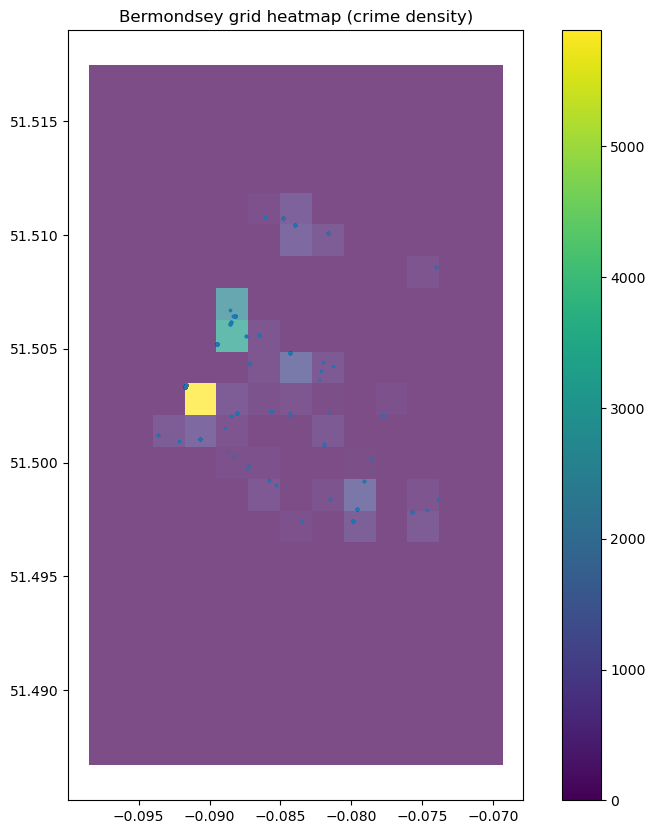

In [8]:
# Convert back to lat/lon for plotting (optional)
grid_ll = grid.to_crs("EPSG:4326")

ax = grid_ll.plot(
    column="crime_density",  # or "crime_count"
    legend=True,
    figsize=(10, 10),
    alpha=0.7
)

# overlay crimes as points (optional)
gdf_crimes_berm.plot(ax=ax, markersize=2, alpha=0.3)

plt.title("Bermondsey grid heatmap (crime density)")
plt.show()


Routes rows: 68 | unique routes: 68
Clubs rows: 7 | unique clubs: 7
Built LineStrings for 68/68 routes (failed=0).


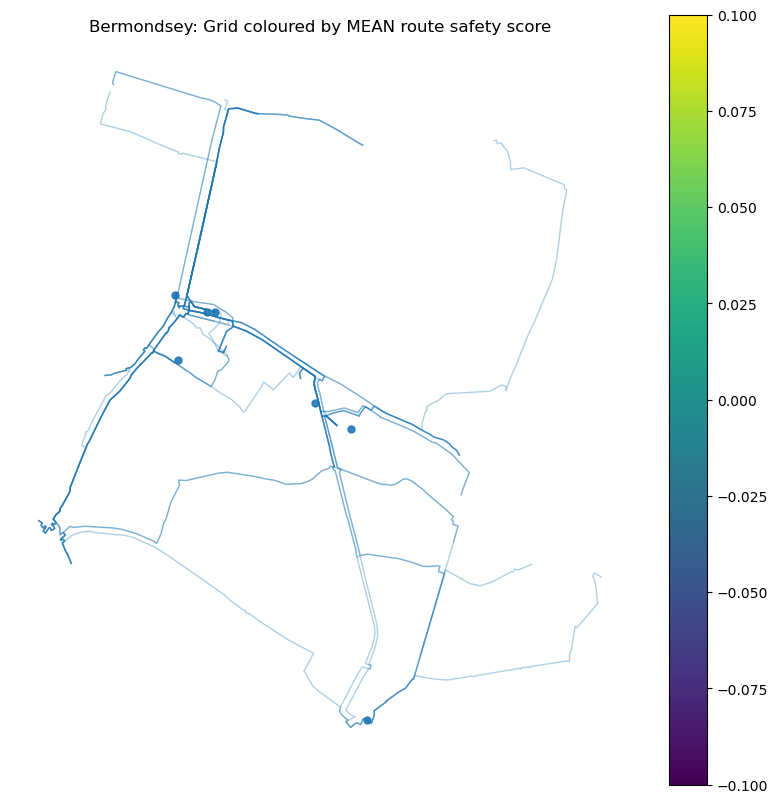

In [11]:
# ============================================================
# FULL PIPELINE: Bermondsey route safety -> grid choropleth map
# - pulls Bermondsey routes + crimes exposure from SQLite
# - computes route safety score
# - decodes route polyline to LineString (handles Google polyline OR JSON coords)
# - builds a metre-based grid around Bermondsey clubs
# - spatial-joins routes -> grid (intersects)
# - aggregates mean safety per grid cell
# - plots choropleth + overlays routes and clubs
# - exports grid as GeoJSON
# ============================================================

from pathlib import Path
import sqlite3
import json

import pandas as pd
import numpy as np

import geopandas as gpd
from shapely.geometry import LineString, box
import matplotlib.pyplot as plt


# ----------------------------
# 0) CONFIG
# ----------------------------
DB_PATH = Path("data/processed/nightclub_safety.db")
assert DB_PATH.exists(), f"Database not found: {DB_PATH.resolve()}"

AREA_NAME = "Bermondsey"

# Adjust to taste:
GRID_CELL_SIZE_M = 250   # grid cell size in metres (150/250/500 are good)
PAD_METRES = 1200        # how far beyond Bermondsey clubs to extend the grid

# Your route polyline column name in routes table:
ROUTE_POLYLINE_COL = "polyline"

# Your route-to-crime link table name (yours appears to be route_crimes)
ROUTE_CRIMES_TABLE = "route_crimes"   # change to "routes_crimes" if needed


# ----------------------------
# 1) SAFE POLYLINE PARSERS
# ----------------------------
def decode_google_polyline_safe(polyline_str: str):
    """Safely decode Google encoded polyline -> list of (lon, lat). Returns [] if invalid."""
    if polyline_str is None:
        return []
    polyline_str = str(polyline_str).strip()
    if polyline_str == "":
        return []

    index, lat, lng = 0, 0, 0
    coords = []
    length = len(polyline_str)

    try:
        while index < length:
            # latitude
            shift, result = 0, 0
            while True:
                if index >= length:
                    return []
                b = ord(polyline_str[index]) - 63
                index += 1
                result |= (b & 0x1f) << shift
                shift += 5
                if b < 0x20:
                    break
            dlat = ~(result >> 1) if (result & 1) else (result >> 1)
            lat += dlat

            # longitude
            shift, result = 0, 0
            while True:
                if index >= length:
                    return []
                b = ord(polyline_str[index]) - 63
                index += 1
                result |= (b & 0x1f) << shift
                shift += 5
                if b < 0x20:
                    break
            dlng = ~(result >> 1) if (result & 1) else (result >> 1)
            lng += dlng

            coords.append((lng / 1e5, lat / 1e5))  # (lon, lat)
    except Exception:
        return []

    return coords


def polyline_to_linestring(poly):
    """
    Accepts:
      - Google encoded polyline string
      - JSON string representing [[lon,lat], ...] or [[lat,lon], ...]
      - Python list/tuple of points already
    Returns: shapely LineString or None.
    """
    if poly is None:
        return None

    # Already list-like
    if isinstance(poly, (list, tuple)):
        pts = poly
    else:
        s = str(poly).strip()
        if s == "" or s.lower() == "none":
            return None

        pts = None

        # JSON coordinate list?
        if s.startswith("["):
            try:
                pts = json.loads(s)
            except Exception:
                pts = None

        # Else try Google decode
        if pts is None:
            pts = decode_google_polyline_safe(s)

    if not pts or len(pts) < 2:
        return None

    first = pts[0]
    if not (isinstance(first, (list, tuple)) and len(first) >= 2):
        return None

    a, b = float(first[0]), float(first[1])

    # Auto-detect (lat,lon) vs (lon,lat) using London-ish heuristic:
    # London lat ~ 51.x (abs > 1), lon ~ -0.x (abs < 5)
    # If first[0] looks like 51 and first[1] looks like -0.1, swap.
    if abs(a) > 1 and abs(b) < 5:
        pts_lonlat = [(float(p[1]), float(p[0])) for p in pts]  # swap
    else:
        pts_lonlat = [(float(p[0]), float(p[1])) for p in pts]

    if len(pts_lonlat) < 2:
        return None

    return LineString(pts_lonlat)


# ----------------------------
# 2) LOAD DATA FROM SQLITE
# ----------------------------
conn = sqlite3.connect(str(DB_PATH))

# Pull Bermondsey routes + polyline + crime exposure
routes_query = f"""
SELECT
    c.club_id,
    c.latitude  AS club_lat,
    c.longitude AS club_lon,

    d.destination_id,
    d.latitude  AS dest_lat,
    d.longitude AS dest_lon,

    r.route_id,
    r.distanceMeters   AS distance_m,
    r.durationSeconds  AS duration_s,
    r.{ROUTE_POLYLINE_COL} AS route_polyline,

    COUNT(rc.crime_id) AS crime_count,
    COUNT(rc.crime_id) / (r.distanceMeters / 1000.0)  AS crimes_per_km,
    COUNT(rc.crime_id) / (r.durationSeconds / 60.0)   AS crimes_per_min

FROM areas a
JOIN clubs c ON a.area_id = c.area_id
JOIN destinations d ON c.club_id = d.club_id
JOIN routes r ON d.destination_id = r.destination_id
LEFT JOIN {ROUTE_CRIMES_TABLE} rc ON r.route_id = rc.route_id
WHERE a.name = '{AREA_NAME}'
GROUP BY
    c.club_id, c.latitude, c.longitude,
    d.destination_id, d.latitude, d.longitude,
    r.route_id, r.distanceMeters, r.durationSeconds, r.{ROUTE_POLYLINE_COL};
"""

df_routes = pd.read_sql_query(routes_query, conn)

# Pull Bermondsey clubs (for bbox + overlay)
clubs_query = f"""
SELECT c.club_id, c.latitude AS club_lat, c.longitude AS club_lon
FROM areas a
JOIN clubs c ON a.area_id = c.area_id
WHERE a.name = '{AREA_NAME}'
AND c.latitude IS NOT NULL AND c.longitude IS NOT NULL;
"""
df_clubs = pd.read_sql_query(clubs_query, conn)

conn.close()

print("Routes rows:", len(df_routes), "| unique routes:", df_routes["route_id"].nunique())
print("Clubs rows:", len(df_clubs), "| unique clubs:", df_clubs["club_id"].nunique())


# ----------------------------
# 3) CLEAN + SAFETY SCORING
# ----------------------------
# numeric
for col in ["distance_m", "duration_s", "crime_count", "crimes_per_km", "crimes_per_min"]:
    df_routes[col] = pd.to_numeric(df_routes[col], errors="coerce")

df_routes.replace([np.inf, -np.inf], np.nan, inplace=True)
df_routes["crimes_per_km"] = df_routes["crimes_per_km"].fillna(0)
df_routes["crimes_per_min"] = df_routes["crimes_per_min"].fillna(0)

def minmax(series):
    s = series.astype(float)
    if s.max() == s.min():
        return pd.Series(np.zeros(len(s)), index=s.index)
    return (s - s.min()) / (s.max() - s.min())

df_routes["crime_km_norm"]  = minmax(df_routes["crimes_per_km"])
df_routes["crime_min_norm"] = minmax(df_routes["crimes_per_min"])
df_routes["dist_norm"]      = minmax(df_routes["distance_m"])
df_routes["dur_norm"]       = minmax(df_routes["duration_s"])

# weights
w_crime_km, w_crime_min, w_dist, w_dur = 0.4, 0.4, 0.1, 0.1

df_routes["risk_score"] = (
    w_crime_km  * df_routes["crime_km_norm"] +
    w_crime_min * df_routes["crime_min_norm"] +
    w_dist      * df_routes["dist_norm"] +
    w_dur       * df_routes["dur_norm"]
)
df_routes["safety_score"] = 1 - df_routes["risk_score"]
df_routes["safety_score_100"] = (df_routes["safety_score"] * 100).round(2)


# ----------------------------
# 4) POLYLINE -> ROUTE GEOMETRY (LineStrings)
# ----------------------------
df_routes["geometry"] = df_routes["route_polyline"].apply(polyline_to_linestring)

failed = df_routes["geometry"].isna().sum()
print(f"Built LineStrings for {len(df_routes) - failed}/{len(df_routes)} routes (failed={failed}).")

gdf_routes = gpd.GeoDataFrame(
    df_routes.dropna(subset=["geometry"]).copy(),
    geometry="geometry",
    crs="EPSG:4326"
)

gdf_clubs = gpd.GeoDataFrame(
    df_clubs.copy(),
    geometry=gpd.points_from_xy(df_clubs["club_lon"], df_clubs["club_lat"]),
    crs="EPSG:4326"
)


# ----------------------------
# 5) BUILD GRID (METRES CRS) AROUND BERMONDSEY
# ----------------------------
routes_m = gdf_routes.to_crs("EPSG:3857")
clubs_m  = gdf_clubs.to_crs("EPSG:3857")

minx, miny, maxx, maxy = clubs_m.total_bounds
bbox = box(minx - PAD_METRES, miny - PAD_METRES, maxx + PAD_METRES, maxy + PAD_METRES)

xs = np.arange(bbox.bounds[0], bbox.bounds[2], GRID_CELL_SIZE_M)
ys = np.arange(bbox.bounds[1], bbox.bounds[3], GRID_CELL_SIZE_M)

cells = []
cell_ids = []
cid = 0
for x in xs:
    for y in ys:
        cells.append(box(x, y, x + GRID_CELL_SIZE_M, y + GRID_CELL_SIZE_M))
        cell_ids.append(cid)
        cid += 1

grid = gpd.GeoDataFrame({"cell_id": cell_ids}, geometry=cells, crs="EPSG:3857")


# ----------------------------
# 6) SPATIAL JOIN ROUTES -> GRID + AGGREGATE MEAN SAFETY
# ----------------------------
join = gpd.sjoin(
    routes_m[["route_id", "safety_score_100", "geometry"]],
    grid,
    predicate="intersects",
    how="left"
)

cell_scores = (
    join.dropna(subset=["cell_id"])
        .groupby("cell_id")
        .agg(
            mean_safety=("safety_score_100", "mean"),
            routes_in_cell=("route_id", "nunique")
        )
        .reset_index()
)

grid = grid.merge(cell_scores, on="cell_id", how="left")
grid["routes_in_cell"] = grid["routes_in_cell"].fillna(0).astype(int)

grid_ll   = grid.to_crs("EPSG:4326")
routes_ll = routes_m.to_crs("EPSG:4326")
clubs_ll  = clubs_m.to_crs("EPSG:4326")


# ----------------------------
# 7) PLOT CHOROPLETH (SAFER = HIGHER)
# ----------------------------
ax = grid_ll.plot(
    column="mean_safety",
    legend=True,
    figsize=(10, 10),
    alpha=0.75
)

# Overlays (optional)
routes_ll.plot(ax=ax, linewidth=1, alpha=0.35)
clubs_ll.plot(ax=ax, markersize=25, alpha=0.9)

plt.title(f"{AREA_NAME}: Grid coloured by MEAN route safety score")
plt.axis("off")
plt.show()





Routes rows: 84 | unique routes: 84
Clubs rows: 9 | unique clubs: 9
Built LineStrings for 84/84 routes (failed=0).


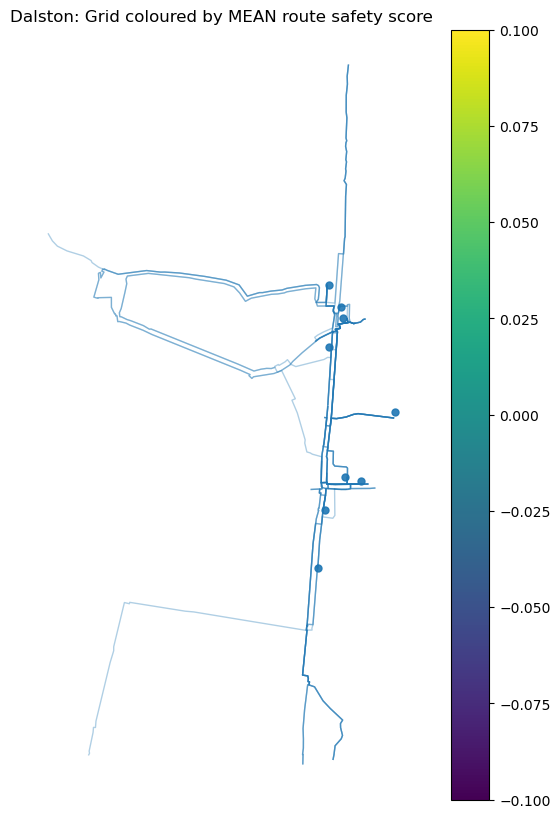

In [12]:
# ============================================================
# FULL PIPELINE: Dalston route safety -> grid choropleth map
# - pulls Dalston routes + crimes exposure from SQLite
# - computes route safety score
# - decodes route polyline to LineString (handles Google polyline OR JSON coords)
# - builds a metre-based grid around Dalston clubs
# - spatial-joins routes -> grid (intersects)
# - aggregates mean safety per grid cell
# - plots choropleth + overlays routes and clubs
# - exports grid as GeoJSON
# ============================================================

from pathlib import Path
import sqlite3
import json

import pandas as pd
import numpy as np

import geopandas as gpd
from shapely.geometry import LineString, box
import matplotlib.pyplot as plt


# ----------------------------
# 0) CONFIG
# ----------------------------
DB_PATH = Path("data/processed/nightclub_safety.db")
assert DB_PATH.exists(), f"Database not found: {DB_PATH.resolve()}"

AREA_NAME = "Dalston"

# Adjust to taste:
GRID_CELL_SIZE_M = 250   # grid cell size in metres (150/250/500 are good)
PAD_METRES = 1200        # how far beyond Dalston clubs to extend the grid

# Your route polyline column name in routes table:
ROUTE_POLYLINE_COL = "polyline"

# Your route-to-crime link table name (yours appears to be route_crimes)
ROUTE_CRIMES_TABLE = "route_crimes"   # change to "routes_crimes" if needed


# ----------------------------
# 1) SAFE POLYLINE PARSERS
# ----------------------------
def decode_google_polyline_safe(polyline_str: str):
    """Safely decode Google encoded polyline -> list of (lon, lat). Returns [] if invalid."""
    if polyline_str is None:
        return []
    polyline_str = str(polyline_str).strip()
    if polyline_str == "":
        return []

    index, lat, lng = 0, 0, 0
    coords = []
    length = len(polyline_str)

    try:
        while index < length:
            # latitude
            shift, result = 0, 0
            while True:
                if index >= length:
                    return []
                b = ord(polyline_str[index]) - 63
                index += 1
                result |= (b & 0x1f) << shift
                shift += 5
                if b < 0x20:
                    break
            dlat = ~(result >> 1) if (result & 1) else (result >> 1)
            lat += dlat

            # longitude
            shift, result = 0, 0
            while True:
                if index >= length:
                    return []
                b = ord(polyline_str[index]) - 63
                index += 1
                result |= (b & 0x1f) << shift
                shift += 5
                if b < 0x20:
                    break
            dlng = ~(result >> 1) if (result & 1) else (result >> 1)
            lng += dlng

            coords.append((lng / 1e5, lat / 1e5))  # (lon, lat)
    except Exception:
        return []

    return coords


def polyline_to_linestring(poly):
    """
    Accepts:
      - Google encoded polyline string
      - JSON string representing [[lon,lat], ...] or [[lat,lon], ...]
      - Python list/tuple of points already
    Returns: shapely LineString or None.
    """
    if poly is None:
        return None

    # Already list-like
    if isinstance(poly, (list, tuple)):
        pts = poly
    else:
        s = str(poly).strip()
        if s == "" or s.lower() == "none":
            return None

        pts = None

        # JSON coordinate list?
        if s.startswith("["):
            try:
                pts = json.loads(s)
            except Exception:
                pts = None

        # Else try Google decode
        if pts is None:
            pts = decode_google_polyline_safe(s)

    if not pts or len(pts) < 2:
        return None

    first = pts[0]
    if not (isinstance(first, (list, tuple)) and len(first) >= 2):
        return None

    a, b = float(first[0]), float(first[1])

    # Auto-detect (lat,lon) vs (lon,lat) using London-ish heuristic:
    # If first[0] looks like 51.x and first[1] looks like -0.x, swap.
    if abs(a) > 1 and abs(b) < 5:
        pts_lonlat = [(float(p[1]), float(p[0])) for p in pts]  # swap
    else:
        pts_lonlat = [(float(p[0]), float(p[1])) for p in pts]

    if len(pts_lonlat) < 2:
        return None

    return LineString(pts_lonlat)


# ----------------------------
# 2) LOAD DATA FROM SQLITE
# ----------------------------
conn = sqlite3.connect(str(DB_PATH))

routes_query = f"""
SELECT
    c.club_id,
    c.latitude  AS club_lat,
    c.longitude AS club_lon,

    d.destination_id,
    d.latitude  AS dest_lat,
    d.longitude AS dest_lon,

    r.route_id,
    r.distanceMeters   AS distance_m,
    r.durationSeconds  AS duration_s,
    r.{ROUTE_POLYLINE_COL} AS route_polyline,

    COUNT(rc.crime_id) AS crime_count,
    COUNT(rc.crime_id) / (r.distanceMeters / 1000.0)  AS crimes_per_km,
    COUNT(rc.crime_id) / (r.durationSeconds / 60.0)   AS crimes_per_min

FROM areas a
JOIN clubs c ON a.area_id = c.area_id
JOIN destinations d ON c.club_id = d.club_id
JOIN routes r ON d.destination_id = r.destination_id
LEFT JOIN {ROUTE_CRIMES_TABLE} rc ON r.route_id = rc.route_id
WHERE a.name = '{AREA_NAME}'
GROUP BY
    c.club_id, c.latitude, c.longitude,
    d.destination_id, d.latitude, d.longitude,
    r.route_id, r.distanceMeters, r.durationSeconds, r.{ROUTE_POLYLINE_COL};
"""

df_routes = pd.read_sql_query(routes_query, conn)

clubs_query = f"""
SELECT c.club_id, c.latitude AS club_lat, c.longitude AS club_lon
FROM areas a
JOIN clubs c ON a.area_id = c.area_id
WHERE a.name = '{AREA_NAME}'
AND c.latitude IS NOT NULL AND c.longitude IS NOT NULL;
"""
df_clubs = pd.read_sql_query(clubs_query, conn)

conn.close()

print("Routes rows:", len(df_routes), "| unique routes:", df_routes["route_id"].nunique())
print("Clubs rows:", len(df_clubs), "| unique clubs:", df_clubs["club_id"].nunique())


# ----------------------------
# 3) CLEAN + SAFETY SCORING
# ----------------------------
for col in ["distance_m", "duration_s", "crime_count", "crimes_per_km", "crimes_per_min"]:
    df_routes[col] = pd.to_numeric(df_routes[col], errors="coerce")

df_routes.replace([np.inf, -np.inf], np.nan, inplace=True)
df_routes["crimes_per_km"] = df_routes["crimes_per_km"].fillna(0)
df_routes["crimes_per_min"] = df_routes["crimes_per_min"].fillna(0)

def minmax(series):
    s = series.astype(float)
    if s.max() == s.min():
        return pd.Series(np.zeros(len(s)), index=s.index)
    return (s - s.min()) / (s.max() - s.min())

df_routes["crime_km_norm"]  = minmax(df_routes["crimes_per_km"])
df_routes["crime_min_norm"] = minmax(df_routes["crimes_per_min"])
df_routes["dist_norm"]      = minmax(df_routes["distance_m"])
df_routes["dur_norm"]       = minmax(df_routes["duration_s"])

w_crime_km, w_crime_min, w_dist, w_dur = 0.4, 0.4, 0.1, 0.1

df_routes["risk_score"] = (
    w_crime_km  * df_routes["crime_km_norm"] +
    w_crime_min * df_routes["crime_min_norm"] +
    w_dist      * df_routes["dist_norm"] +
    w_dur       * df_routes["dur_norm"]
)
df_routes["safety_score"] = 1 - df_routes["risk_score"]
df_routes["safety_score_100"] = (df_routes["safety_score"] * 100).round(2)


# ----------------------------
# 4) POLYLINE -> ROUTE GEOMETRY (LineStrings)
# ----------------------------
df_routes["geometry"] = df_routes["route_polyline"].apply(polyline_to_linestring)

failed = df_routes["geometry"].isna().sum()
print(f"Built LineStrings for {len(df_routes) - failed}/{len(df_routes)} routes (failed={failed}).")

gdf_routes = gpd.GeoDataFrame(
    df_routes.dropna(subset=["geometry"]).copy(),
    geometry="geometry",
    crs="EPSG:4326"
)

gdf_clubs = gpd.GeoDataFrame(
    df_clubs.copy(),
    geometry=gpd.points_from_xy(df_clubs["club_lon"], df_clubs["club_lat"]),
    crs="EPSG:4326"
)


# ----------------------------
# 5) BUILD GRID (METRES CRS) AROUND DALSTON
# ----------------------------
routes_m = gdf_routes.to_crs("EPSG:3857")
clubs_m  = gdf_clubs.to_crs("EPSG:3857")

minx, miny, maxx, maxy = clubs_m.total_bounds
bbox = box(minx - PAD_METRES, miny - PAD_METRES, maxx + PAD_METRES, maxy + PAD_METRES)

xs = np.arange(bbox.bounds[0], bbox.bounds[2], GRID_CELL_SIZE_M)
ys = np.arange(bbox.bounds[1], bbox.bounds[3], GRID_CELL_SIZE_M)

cells = []
cell_ids = []
cid = 0
for x in xs:
    for y in ys:
        cells.append(box(x, y, x + GRID_CELL_SIZE_M, y + GRID_CELL_SIZE_M))
        cell_ids.append(cid)
        cid += 1

grid = gpd.GeoDataFrame({"cell_id": cell_ids}, geometry=cells, crs="EPSG:3857")


# ----------------------------
# 6) SPATIAL JOIN ROUTES -> GRID + AGGREGATE MEAN SAFETY
# ----------------------------
join = gpd.sjoin(
    routes_m[["route_id", "safety_score_100", "geometry"]],
    grid,
    predicate="intersects",
    how="left"
)

cell_scores = (
    join.dropna(subset=["cell_id"])
        .groupby("cell_id")
        .agg(
            mean_safety=("safety_score_100", "mean"),
            routes_in_cell=("route_id", "nunique")
        )
        .reset_index()
)

grid = grid.merge(cell_scores, on="cell_id", how="left")
grid["routes_in_cell"] = grid["routes_in_cell"].fillna(0).astype(int)

grid_ll   = grid.to_crs("EPSG:4326")
routes_ll = routes_m.to_crs("EPSG:4326")
clubs_ll  = clubs_m.to_crs("EPSG:4326")


# ----------------------------
# 7) PLOT CHOROPLETH (SAFER = HIGHER)
# ----------------------------
ax = grid_ll.plot(
    column="mean_safety",
    legend=True,
    figsize=(10, 10),
    alpha=0.75
)

routes_ll.plot(ax=ax, linewidth=1, alpha=0.35)
clubs_ll.plot(ax=ax, markersize=25, alpha=0.9)

plt.title(f"{AREA_NAME}: Grid coloured by MEAN route safety score")
plt.axis("off")
plt.show()




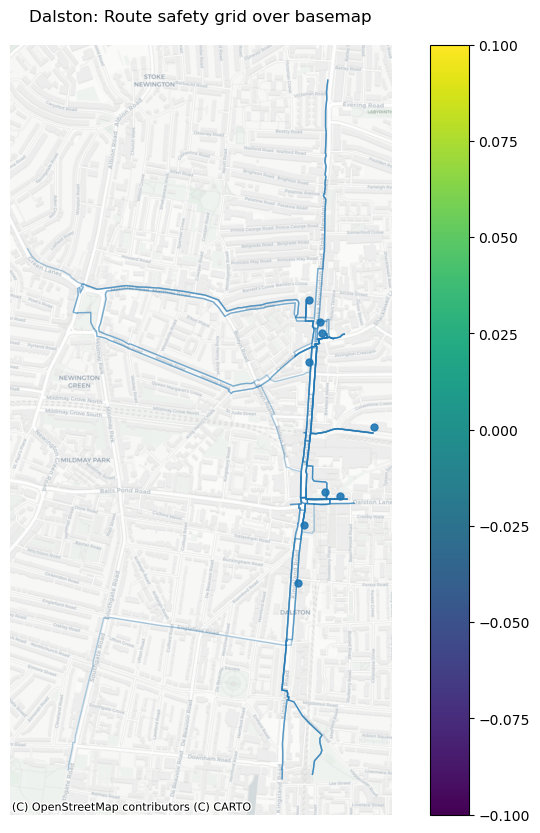

In [18]:
import contextily as cx
import matplotlib.pyplot as plt

# contextily needs Web Mercator
grid_web   = grid_ll.to_crs(epsg=3857)
routes_web = routes_ll.to_crs(epsg=3857)
clubs_web  = clubs_ll.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(10, 10))

# Plot grid choropleth
grid_web.plot(
    ax=ax,
    column="mean_safety",
    legend=True,
    alpha=0.55
)

# Overlay routes + clubs
routes_web.plot(ax=ax, linewidth=1, alpha=0.35)
clubs_web.plot(ax=ax, markersize=25, alpha=0.9)

# Add basemap tiles underneath
cx.add_basemap(ax, source=cx.providers.CartoDB.Positron)

ax.set_axis_off()
plt.title(f"{AREA_NAME}: Route safety grid over basemap")


plt.show()

In [22]:
import pandas as pd

grid_ll = grid_ll.copy()
grid_ll["mean_safety"] = pd.to_numeric(grid_ll["mean_safety"], errors="coerce")

grid_data = grid_ll[grid_ll["mean_safety"].notna()].copy()

print("Cells with data:", len(grid_data))

m = grid_data.explore(
    column="mean_safety",
    tiles="CartoDB positron",
    cmap="RdYlGn",
    legend=True,
    tooltip=["mean_safety", "routes_in_cell"],
    style_kwds={"fillOpacity": 0.55, "weight": 0.2}
)

routes_ll.explore(m=m, color="black", weight=2, opacity=0.3)
clubs_ll.explore(m=m, color="blue", marker_kwds={"radius": 4})

m




Cells with data: 0


/tmp/ipykernel_4342/3084814799.py:10: UserWarning: The GeoSeries you are attempting to plot is composed of empty geometries. Nothing has been displayed.
  m = grid_data.explore(


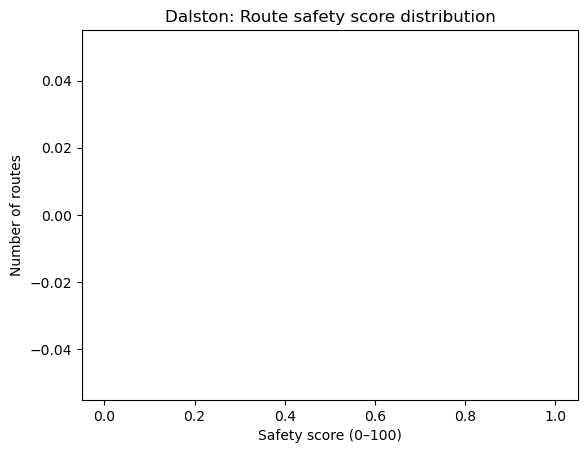

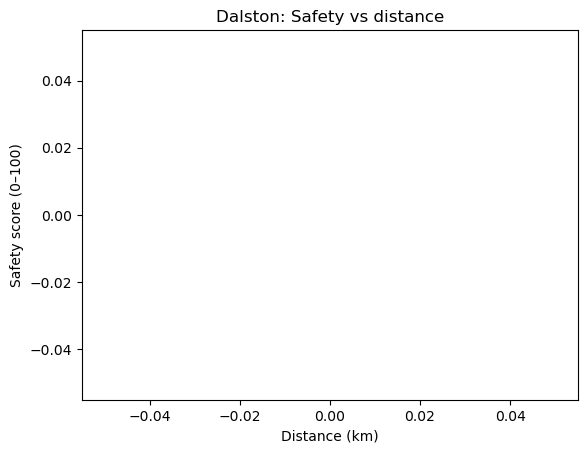

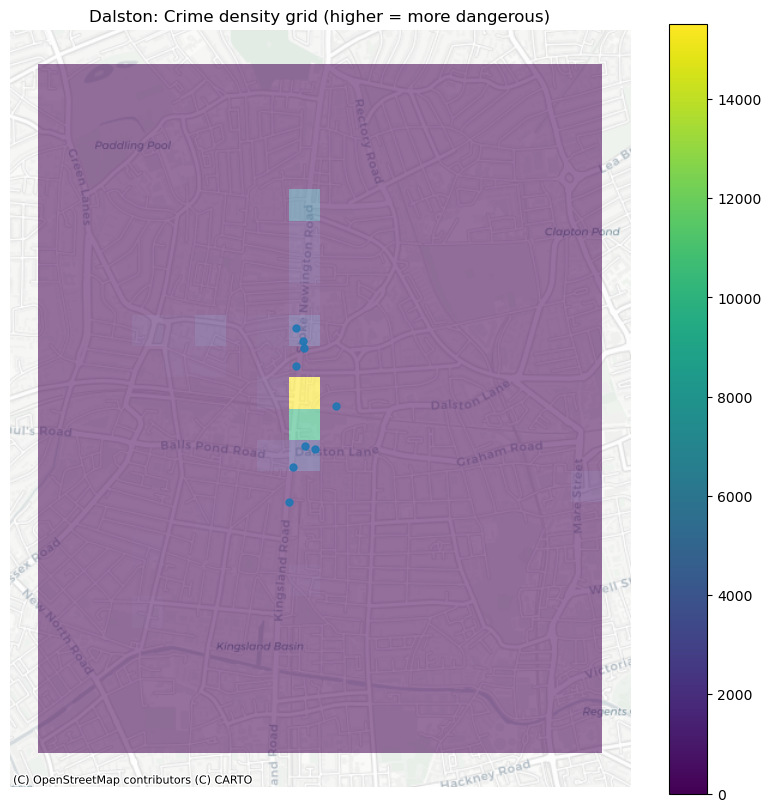

Saved CSV + GeoJSON outputs.


In [23]:
# =========================
# FULL WORKING PIPELINE (DALSTON / BERMONDSEY etc.)
# - Route safety scoring (works without polylines)
# - Grid "area safety" map from crime density (robust)
# - Basic visualisations (hist + scatter + basemap overlay)
# =========================

from pathlib import Path
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import geopandas as gpd
from shapely.geometry import box
import contextily as cx


# -------------------------
# 0) SETTINGS
# -------------------------
DB_PATH = Path("data/processed/nightclub_safety.db")
assert DB_PATH.exists(), f"DB not found: {DB_PATH.resolve()}"

AREA_NAME = "Dalston"      # change to "Bermondsey" etc.
GRID_CELL_SIZE_M = 250     # 150/250/500
PAD_METRES = 2000          # enlarge if you want wider map


# -------------------------
# 1) CONNECT + PULL ROUTE METRICS (AREA ONLY)
# -------------------------
conn = sqlite3.connect(str(DB_PATH))

# NOTE: your link table appears to be route_crimes (working for you)
route_query = f"""
SELECT
    c.club_id,
    r.route_id,
    r.distanceMeters   AS distance_m,
    r.durationSeconds  AS duration_s,

    COUNT(rc.crime_id) AS crime_count,
    COUNT(rc.crime_id) / (r.distanceMeters / 1000.0)  AS crimes_per_km,
    COUNT(rc.crime_id) / (r.durationSeconds / 60.0)   AS crimes_per_min

FROM areas a
JOIN clubs c ON a.area_id = c.area_id
JOIN destinations d ON c.club_id = d.club_id
JOIN routes r ON d.destination_id = r.destination_id
LEFT JOIN route_crimes rc ON r.route_id = rc.route_id
WHERE a.name = '{AREA_NAME}'
GROUP BY c.club_id, r.route_id, r.distanceMeters, r.durationSeconds;
"""

df_routes = pd.read_sql_query(route_query, conn)

# Pull clubs (for bounding box + map overlay)
clubs_query = f"""
SELECT c.club_id, c.latitude AS club_lat, c.longitude AS club_lon
FROM areas a
JOIN clubs c ON a.area_id = c.area_id
WHERE a.name = '{AREA_NAME}'
AND c.latitude IS NOT NULL AND c.longitude IS NOT NULL;
"""
df_clubs = pd.read_sql_query(clubs_query, conn)

# Pull crimes (points) — we’ll clip to a bbox around the area’s clubs
crimes_query = """
SELECT crime_id, category, month, latitude, longitude
FROM crimes
WHERE latitude IS NOT NULL AND longitude IS NOT NULL;
"""
df_crimes = pd.read_sql_query(crimes_query, conn)

conn.close()


# -------------------------
# 2) CLEAN ROUTE METRICS + SAFETY SCORE
# -------------------------
for col in ["distance_m", "duration_s", "crime_count", "crimes_per_km", "crimes_per_min"]:
    df_routes[col] = pd.to_numeric(df_routes[col], errors="coerce")

df_routes.replace([np.inf, -np.inf], np.nan, inplace=True)
df_routes["crimes_per_km"] = df_routes["crimes_per_km"].fillna(0)
df_routes["crimes_per_min"] = df_routes["crimes_per_min"].fillna(0)

def minmax(series):
    s = series.astype(float)
    if len(s) == 0 or s.max() == s.min():
        return pd.Series(np.zeros(len(s)), index=s.index)
    return (s - s.min()) / (s.max() - s.min())

df_routes["crime_km_norm"]  = minmax(df_routes["crimes_per_km"])
df_routes["crime_min_norm"] = minmax(df_routes["crimes_per_min"])
df_routes["distance_norm"]  = minmax(df_routes["distance_m"])
df_routes["duration_norm"]  = minmax(df_routes["duration_s"])

w_crime_km, w_crime_min, w_dist, w_dur = 0.4, 0.4, 0.1, 0.1

df_routes["risk_score"] = (
    w_crime_km  * df_routes["crime_km_norm"] +
    w_crime_min * df_routes["crime_min_norm"] +
    w_dist      * df_routes["distance_norm"] +
    w_dur       * df_routes["duration_norm"]
)

df_routes["safety_score"] = 1 - df_routes["risk_score"]
df_routes["safety_score_100"] = (df_routes["safety_score"] * 100).round(2)


# -------------------------
# 3) BUILD "AREA SAFETY" GRID FROM CRIME DENSITY (ROBUST)
# -------------------------
# Convert clubs/crimes to GeoDataFrames
gdf_clubs = gpd.GeoDataFrame(
    df_clubs.copy(),
    geometry=gpd.points_from_xy(df_clubs["club_lon"], df_clubs["club_lat"]),
    crs="EPSG:4326"
)

gdf_crimes = gpd.GeoDataFrame(
    df_crimes.copy(),
    geometry=gpd.points_from_xy(df_crimes["longitude"], df_crimes["latitude"]),
    crs="EPSG:4326"
)

# Work in metres CRS
clubs_m = gdf_clubs.to_crs("EPSG:3857")
crimes_m = gdf_crimes.to_crs("EPSG:3857")

# BBox around the area based on clubs
minx, miny, maxx, maxy = clubs_m.total_bounds
bbox = box(minx - PAD_METRES, miny - PAD_METRES, maxx + PAD_METRES, maxy + PAD_METRES)
bbox_gdf = gpd.GeoDataFrame(geometry=[bbox], crs="EPSG:3857")

# Clip crimes to bbox
crimes_clip = crimes_m[crimes_m.within(bbox)].copy()

# Build grid
xs = np.arange(bbox.bounds[0], bbox.bounds[2], GRID_CELL_SIZE_M)
ys = np.arange(bbox.bounds[1], bbox.bounds[3], GRID_CELL_SIZE_M)

cells = []
cell_ids = []
cid = 0
for x in xs:
    for y in ys:
        cells.append(box(x, y, x + GRID_CELL_SIZE_M, y + GRID_CELL_SIZE_M))
        cell_ids.append(cid)
        cid += 1

grid = gpd.GeoDataFrame({"cell_id": cell_ids}, geometry=cells, crs="EPSG:3857")

# Count crimes per cell
join = gpd.sjoin(crimes_clip, grid, predicate="within", how="left")
cell_counts = join.groupby("cell_id").size().rename("crime_count").reset_index()

grid = grid.merge(cell_counts, on="cell_id", how="left")
grid["crime_count"] = grid["crime_count"].fillna(0)

# Crime density per km^2 (fairer than raw counts)
grid["area_km2"] = grid.area / 1e6
grid["crime_density"] = grid["crime_count"] / grid["area_km2"]

# Convert to lat/lon for any non-contextily uses (contextily wants 3857, so keep web)
grid_web = grid.copy()
clubs_web = clubs_m.copy()


# -------------------------
# 4) STEP 9-STYLE BASIC VISUALISATIONS (FROM YOUR ORIGINAL STYLE)
# -------------------------

# (A) Histogram of route safety scores
plt.figure()
plt.hist(df_routes["safety_score_100"].dropna(), bins=20)
plt.xlabel("Safety score (0–100)")
plt.ylabel("Number of routes")
plt.title(f"{AREA_NAME}: Route safety score distribution")
plt.show()

# (B) Scatter: safety vs distance
plt.figure()
plt.scatter(df_routes["distance_m"] / 1000.0, df_routes["safety_score_100"])
plt.xlabel("Distance (km)")
plt.ylabel("Safety score (0–100)")
plt.title(f"{AREA_NAME}: Safety vs distance")
plt.show()

# (C) Map: grid crime density over basemap (safer = lower density)
fig, ax = plt.subplots(figsize=(10, 10))

grid_web.plot(
    ax=ax,
    column="crime_density",     # higher density = more dangerous
    legend=True,
    alpha=0.55
)

# Overlay clubs
clubs_web.plot(ax=ax, markersize=25, alpha=0.9)

# Basemap
cx.add_basemap(ax, source=cx.providers.CartoDB.Positron)

ax.set_axis_off()
ax.set_title(f"{AREA_NAME}: Crime density grid (higher = more dangerous)")
plt.show()


# -------------------------
# 5) OPTIONAL: EXPORTS
# -------------------------
df_routes.to_csv(f"{AREA_NAME.lower()}_route_safety_scores.csv", index=False)
grid_web.to_crs("EPSG:4326").to_file(f"{AREA_NAME.lower()}_crime_density_grid.geojson", driver="GeoJSON")

print("Saved CSV + GeoJSON outputs.")
